# LLaVA-Style Stage 2: LoRA Fine-Tuning the LLM

This is the third notebook in the sequence:

1. `minimal_vlm_from_scratch.ipynb` — ViT + text decoder, both trained from scratch. Vague, repetitive captions.
2. `minimal_vlm_llava_style.ipynb` — frozen CLIP ViT-B/32 + frozen SmolLM2-135M, only the projector trained (LLaVA's Stage 1). Fluent but possibly under-grounded captions; teacher-forced loss/perplexity barely moved, for reasons discussed in that notebook's closing notes.
3. **This notebook** — LLaVA's actual Stage 2: keep the vision encoder frozen, but now also let the LLM adapt, via **LoRA** rather than a full fine-tune (full fine-tuning 134M params on a laptop, on 8K images, would be slow and prone to overfitting/catastrophic forgetting — LoRA is the practical choice here, and it's the same technique from your own PEFT/LoRA background).

**What changes vs. Stage 1:**

| | Stage 1 | Stage 2 (this notebook) |
|---|---|---|
| Vision encoder | Frozen | Frozen (unchanged) |
| Projector | Trained | Trained (warm-started from Stage 1's weights, if available) |
| LLM | Fully frozen | Frozen base weights + trainable **LoRA adapters** on attention/MLP projections |
| Trainable params | ~443K (projector only, ~0.2%) | Projector + LoRA adapters (still a small fraction of the 222M total — printed below) |

**Why warm-start the projector from Stage 1:** LLaVA's actual two-stage recipe trains the projector first (with everything else frozen) specifically so it's already roughly aligned before the LLM starts adapting — unfreezing the LLM alongside a *randomly initialized* projector risks the LLM "fine-tuning around" noisy, not-yet-useful visual tokens. Save your Stage 1 notebook's projector weights (one line, shown below) and load them here for a fair test of what Stage 2 specifically adds.


## 0. One-time addition to your Stage 1 notebook

Add this cell at the end of `minimal_vlm_llava_style.ipynb` (after training) to save the projector so this notebook can warm-start from it:

```python
torch.save(model.projector.state_dict(), "stage1_projector.pt")
```

If you don't have this saved, this notebook still works — it just falls back to a randomly-initialized projector (set `WARM_START_PROJECTOR = False` below), which is still a valid experiment, just not the exact LLaVA recipe.


## 1. Setup

In [2]:
import os
import math
import random
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import matplotlib.pyplot as plt

from transformers import CLIPVisionModel, AutoImageProcessor, AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType

torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)


Using device: mps


## 2. Configuration

In [ ]:
VISION_MODEL_ID = "openai/clip-vit-base-patch32"
LLM_MODEL_ID = "HuggingFaceTB/SmolLM2-135M"

IMAGE_DIR = "../data/flickr8k/Images"
CAPTIONS_FILE = "../data/flickr8k/captions.txt"

MAX_TEXT_LEN = 32
BATCH_SIZE = 16
NUM_EPOCHS = 2

# Two learning rates: LoRA adapters are new/randomly-initialized (like the
# projector was in Stage 1) and can tolerate a higher LR; the projector is
# already-trained (if warm-started) and should move more gently so Stage 2
# doesn't undo Stage 1's alignment work in the first few steps.
LORA_LR = 2e-4
PROJECTOR_LR = 5e-5

# LoRA hyperparameters -- rank 8 is a common, cheap starting point; increase
# if Stage 2 clearly underfits relative to Stage 1's already-low loss.
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
LORA_TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

WARM_START_PROJECTOR = True   # set False if you didn't save stage1_projector.pt
STAGE1_PROJECTOR_PATH = "stage1_projector.pt"


## 3. Load the frozen vision encoder (identical to Stage 1)

In [4]:
image_processor = AutoImageProcessor.from_pretrained(VISION_MODEL_ID, use_fast=True)
vision_encoder = CLIPVisionModel.from_pretrained(VISION_MODEL_ID, dtype=torch.float32).to(device)
vision_encoder.requires_grad_(False)
vision_encoder.eval()

vision_hidden_size = vision_encoder.config.hidden_size
num_visual_tokens = (vision_encoder.config.image_size // vision_encoder.config.patch_size) ** 2 + 1
print(f"Vision encoder: {VISION_MODEL_ID} (frozen, unchanged from Stage 1)")
print(f"  hidden size: {vision_hidden_size}, visual tokens per image: {num_visual_tokens}")


[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_at

Vision encoder: openai/clip-vit-base-patch32 (frozen, unchanged from Stage 1)
  hidden size: 768, visual tokens per image: 50


## 4. Load the LLM and wrap it with LoRA

This is the key architectural difference from Stage 1. `get_peft_model` freezes every base parameter automatically and injects small trainable low-rank adapter matrices into the named `target_modules` -- it does *not* modify the frozen weights themselves, so if you ever want a clean frozen LLM again, you just don't load the adapters.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL_ID, dtype=torch.float32).to(device)
base_llm.config.pad_token_id = tokenizer.pad_token_id

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGET_MODULES,
)
llm = get_peft_model(base_llm, lora_config)

llm_total = sum(p.numel() for p in llm.parameters())
llm_trainable = sum(p.numel() for p in llm.parameters() if p.requires_grad)
print(f"LLM: {LLM_MODEL_ID} + LoRA (r={LORA_R})")
print(f"  total params: {llm_total:,}")
print(f"  trainable (LoRA adapters only): {llm_trainable:,}  ({100 * llm_trainable / llm_total:.3f}% of LLM)")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

LLM: HuggingFaceTB/SmolLM2-135M + LoRA (r=8)
  total params: 136,957,248
  trainable (LoRA adapters only): 2,442,240  (1.783% of LLM)


## 5. Dataset (identical to Stage 1 -- this is what keeps the val split, and therefore the fixed comparison images, consistent across notebooks)

In [6]:
class CaptionDataset(torch.utils.data.Dataset):
    def __init__(self, image_dir, captions_file, tokenizer, image_processor, max_len):
        self.image_dir = Path(image_dir)
        self.tokenizer = tokenizer
        self.image_processor = image_processor
        self.max_len = max_len
        self.samples = []

        with open(captions_file, "r", encoding="utf-8") as f:
            lines = f.readlines()
        if lines and "," in lines[0] and lines[0].lower().startswith("image"):
            lines = lines[1:]
        for line in lines:
            line = line.strip()
            if not line:
                continue
            image_name, caption = line.split(",", 1)
            self.samples.append((image_name.strip(), caption.strip()))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_name, caption = self.samples[idx]
        image = Image.open(self.image_dir / image_name).convert("RGB")
        pixel_values = self.image_processor(images=image, return_tensors="pt")["pixel_values"][0]

        ids = self.tokenizer(caption, add_special_tokens=False)["input_ids"]
        ids = ids[: self.max_len - 1] + [self.tokenizer.eos_token_id]
        attn = [1] * len(ids)
        pad_len = self.max_len - len(ids)
        ids = ids + [self.tokenizer.pad_token_id] * pad_len
        attn = attn + [0] * pad_len

        return (pixel_values, torch.tensor(ids, dtype=torch.long), torch.tensor(attn, dtype=torch.long))


dataset = CaptionDataset(IMAGE_DIR, CAPTIONS_FILE, tokenizer, image_processor, MAX_TEXT_LEN)
print(f"Total (image, caption) pairs: {len(dataset)}")

# Same seed as Stage 1 -> same train/val split -> val_set[i] is the same image in both notebooks.
val_size = max(1, int(0.05 * len(dataset)))
train_size = len(dataset) - val_size
train_set, val_set = torch.utils.data.random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"train batches: {len(train_loader)}  val batches: {len(val_loader)}")


Total (image, caption) pairs: 40455
train batches: 2402  val batches: 127


## 6. The Stage 2 model

Structurally the same `_visual_tokens` / `forward` / `generate` shape as Stage 1's `MiniLLaVA` -- the only difference is `self.llm` is now the LoRA-wrapped model instead of a fully frozen one, and `train()` no longer forces the LLM into `eval()` mode (LoRA's dropout and adapter layers need to see training mode to behave correctly during training).

In [7]:
class MiniLLaVAStage2(nn.Module):
    def __init__(self, vision_encoder, llm, tokenizer):
        super().__init__()
        self.vision_encoder = vision_encoder
        self.llm = llm  # LoRA-wrapped
        self.tokenizer = tokenizer
        self.projector = nn.Linear(vision_encoder.config.hidden_size, llm.config.hidden_size)

    def train(self, mode=True):
        super().train(mode)
        self.vision_encoder.eval()  # vision encoder stays frozen/eval always
        return self

    def _visual_tokens(self, pixel_values):
        with torch.no_grad():
            vision_features = self.vision_encoder(pixel_values=pixel_values).last_hidden_state
        return self.projector(vision_features)

    def forward(self, pixel_values, input_ids, attention_mask):
        visual_tokens = self._visual_tokens(pixel_values)
        text_embeds = self.llm.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([visual_tokens, text_embeds], dim=1)

        V = visual_tokens.shape[1]
        full_attention_mask = torch.cat(
            [torch.ones(pixel_values.shape[0], V, dtype=torch.long, device=pixel_values.device), attention_mask],
            dim=1,
        )

        text_labels = input_ids.clone()
        text_labels[attention_mask == 0] = -100
        visual_labels = torch.full((pixel_values.shape[0], V), -100, dtype=torch.long, device=pixel_values.device)
        labels = torch.cat([visual_labels, text_labels], dim=1)

        outputs = self.llm(inputs_embeds=inputs_embeds, attention_mask=full_attention_mask, labels=labels)
        return outputs.logits, outputs.loss

    @torch.no_grad()
    def generate(self, pixel_values, max_new_tokens=32):
        self.eval()
        visual_tokens = self._visual_tokens(pixel_values)
        attention_mask = torch.ones(visual_tokens.shape[:2], dtype=torch.long, device=pixel_values.device)
        return self.llm.generate(
            inputs_embeds=visual_tokens,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=self.tokenizer.pad_token_id,
            eos_token_id=self.tokenizer.eos_token_id,
        )


## 7. Instantiate, warm-start the projector, and set up the optimizer with two param groups

In [8]:
model = MiniLLaVAStage2(vision_encoder, llm, tokenizer).to(device)

if WARM_START_PROJECTOR and Path(STAGE1_PROJECTOR_PATH).exists():
    model.projector.load_state_dict(torch.load(STAGE1_PROJECTOR_PATH, map_location=device))
    print(f"Warm-started projector from {STAGE1_PROJECTOR_PATH}")
else:
    print("Projector randomly initialized (no Stage 1 checkpoint loaded)")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters (projector + LoRA): {trainable_params:,}  ({100 * trainable_params / total_params:.3f}% of total)")

# Two param groups -> two learning rates, as discussed in Section 2.
optimizer = torch.optim.AdamW([
    {"params": model.projector.parameters(), "lr": PROJECTOR_LR},
    {"params": [p for n, p in model.llm.named_parameters() if p.requires_grad], "lr": LORA_LR},
])


Warm-started projector from stage1_projector.pt
Total parameters: 224,856,192
Trainable parameters (projector + LoRA): 2,885,184  (1.283% of total)


## 8. Quick smoke test (synthetic data) before touching real data

In [9]:
_pixel_values = torch.randn(2, 3, image_processor.crop_size["height"], image_processor.crop_size["width"]).to(device)
_input_ids = torch.randint(0, tokenizer.vocab_size, (2, MAX_TEXT_LEN)).to(device)
_attention_mask = torch.ones_like(_input_ids)

model.train()
_logits, _loss = model(_pixel_values, _input_ids, _attention_mask)
print("logits shape:", _logits.shape)
print("loss:", _loss.item())

_loss.backward()
proj_grad = any(p.grad is not None and p.grad.abs().sum() > 0 for p in model.projector.parameters())
lora_grad = any(p.grad is not None and p.grad.abs().sum() > 0 for n, p in model.llm.named_parameters() if "lora_" in n)
vision_grad = any(p.grad is not None for p in model.vision_encoder.parameters())
print(f"Projector received gradients: {proj_grad}")
print(f"LoRA adapters received gradients: {lora_grad}")
print(f"Vision encoder received gradients (should be False): {vision_grad}")
assert proj_grad and lora_grad and not vision_grad
print("Smoke test passed.")

model.zero_grad()
del _pixel_values, _input_ids, _attention_mask, _logits, _loss


logits shape: torch.Size([2, 82, 49152])
loss: 13.810258865356445
Projector received gradients: True
LoRA adapters received gradients: True
Vision encoder received gradients (should be False): False
Smoke test passed.


## 9. Training loop (same shape as Stage 1's, gradient clipping applied to all trainable params)

In [10]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_tokens = 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    with context:
        for pixel_values, input_ids, attention_mask in loader:
            pixel_values = pixel_values.to(device)
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)

            _, loss = model(pixel_values, input_ids, attention_mask)

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
                optimizer.step()

            n_tok = attention_mask.sum().item()
            total_loss += loss.item() * n_tok
            total_tokens += n_tok
    return total_loss / max(total_tokens, 1)


history = {"train_loss": [], "val_loss": []}
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch}/{NUM_EPOCHS} -- train_loss: {train_loss:.4f}  val_loss: {val_loss:.4f}")


Epoch 1/2 -- train_loss: 2.1588  val_loss: 2.1601
Epoch 2/2 -- train_loss: 2.0124  val_loss: 2.1131


## 10. Plot the training curve

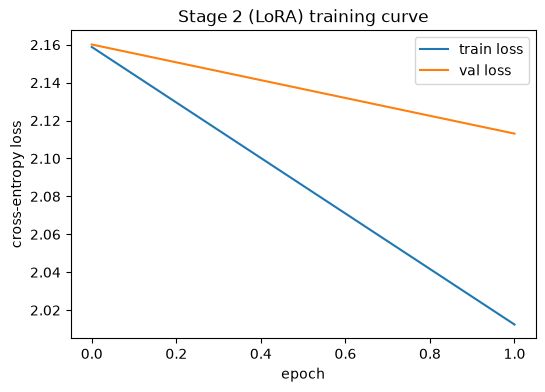

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Stage 2 (LoRA) training curve")
plt.legend()
plt.show()


## 11. Quantitative comparison on the SAME fixed images used in Stage 1

This is the piece that turns "sounds better" into a number. `eval_utils.py` (same file, shared across all three notebooks) fixes the exact validation indices, so `val_set[i]` here is the identical image `val_set[i]` referred to in Stage 1 -- copy this cell into Stage 1 and the from-scratch notebook too, if you haven't already, to get all three numbers side by side.

In [12]:
import sys
sys.path.insert(0, ".")  # adjust if eval_utils.py lives elsewhere

# Reload in case this kernel already imported an older eval_utils.py earlier in
# this session -- Python caches modules, so editing the file on disk alone
# wouldn't be picked up by an already-running kernel without this.
import importlib
import eval_utils
importlib.reload(eval_utils)
from eval_utils import evaluate_fixed_set, build_reference_lookup, save_result

reference_lookup = build_reference_lookup(CAPTIONS_FILE)

def generate_and_decode(val_set, idx):
    pixel_values, _input_ids, _attention_mask = val_set.dataset[val_set.indices[idx]]
    generated_ids = model.generate(pixel_values.unsqueeze(0).to(device), max_new_tokens=MAX_TEXT_LEN)
    return tokenizer.decode(generated_ids[0], skip_special_tokens=True)

stage2_results = evaluate_fixed_set(val_set, generate_and_decode, reference_lookup)
print(f"\nStage 2 (LoRA) corpus BLEU-4 on fixed set: {stage2_results['bleu4']:.4f}")
print("Compare this number directly against Stage 1's BLEU-4 on the same 10 images.")

# Persist to the shared comparison file (see "Where can I see the comparison?" --
# each notebook runs in its own kernel, so this file is what ties all three together).
save_result("Stage 2 (LoRA)", stage2_results)


Corpus BLEU-4 over 10 fixed images: 0.4282

  [1459032057_97e73ed6ab.jpg]
    generated: A little girl is eating a cake .
    reference: A girl in a striped shirt holds a bun to her mouth .
  [1178705300_c224d9a4f1.jpg]
    generated: A dog jumps into a pool .
    reference: a brown dog jumping into a pool after a bloe ball .
  [2206594874_5e0087c6b7.jpg]
    generated: A man and a woman sit at a table .
    reference: A couple sits at a cramped table in a busy restaurant .
  [3376809186_4e26d880b7.jpg]
    generated: A group of people are walking through the water .
    reference: A group of people are in the water .
  [783994497_4f6885454d.jpg]
    generated: Two men are sitting at a counter .
    reference: A group of people are getting fountain drinks at a convenience store .
  [2455528149_6c3477fd33.jpg]
    generated: A woman is standing in front of a group of people .
    reference: A delivery man is passing by two people at an art gallery .
  [1294578091_2ad02fea91.jpg]
    gen

## 12. Qualitative inference on a few images (with teacher-forced loss/perplexity, same caveat as Stage 1 applies)

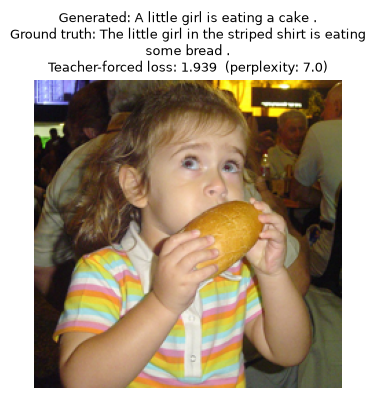

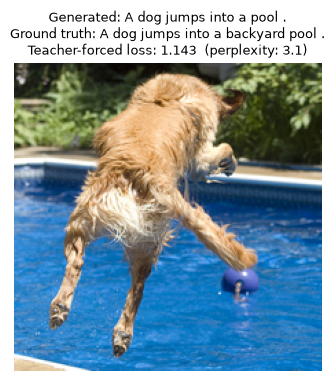

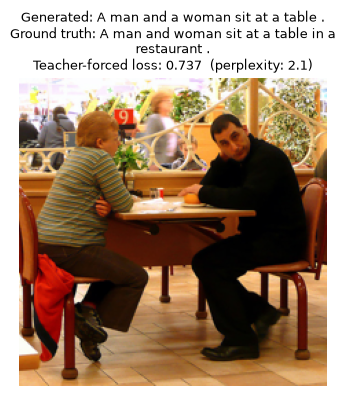

In [13]:
@torch.no_grad()
def caption_loss(pixel_values, input_ids, attention_mask):
    model.eval()
    _, loss = model(pixel_values.unsqueeze(0).to(device), input_ids.unsqueeze(0).to(device), attention_mask.unsqueeze(0).to(device))
    return loss.item()


def show_prediction(dataset_obj, idx):
    pixel_values, input_ids, attention_mask = dataset_obj[idx]
    generated_ids = model.generate(pixel_values.unsqueeze(0).to(device), max_new_tokens=MAX_TEXT_LEN)
    caption = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
    ground_truth = tokenizer.decode(input_ids, skip_special_tokens=True)
    loss = caption_loss(pixel_values, input_ids, attention_mask)
    perplexity = math.exp(loss)

    mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
    std = torch.tensor(image_processor.image_std).view(3, 1, 1)
    img_display = (pixel_values * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    plt.figure(figsize=(4, 4))
    plt.imshow(img_display)
    plt.axis("off")
    plt.title(
        f"Generated: {caption}\nGround truth: {ground_truth}\n"
        f"Teacher-forced loss: {loss:.3f}  (perplexity: {perplexity:.1f})",
        fontsize=9, wrap=True,
    )
    plt.show()


# Same fixed indices as the BLEU evaluation above, for a consistent story.
for i in range(3):
    show_prediction(val_set.dataset, val_set.indices[i])


## 13. Notes for the reading log / report

- **What Stage 2 adds over Stage 1:** the LLM is no longer fully frozen — LoRA adapters on its attention and MLP projections (plus the warm-started projector) are trainable, letting the language model itself adapt slightly to the visual conditioning task, rather than relying purely on the projector to do all the work of making visual tokens "speak the LLM's language."
- **Why LoRA instead of a full fine-tune:** full fine-tuning 134M parameters on ~8K images, on a laptop, is both slow and a good way to overfit or partially erase SmolLM2's general language ability (catastrophic forgetting) for very little data-scale benefit. LoRA constrains the update to a small, low-rank subspace, which is both cheaper and a form of regularization.
- **Two learning rates, deliberately:** the LoRA adapters start from zero-initialized deltas (no prior training), so they can tolerate a higher LR (`LORA_LR`); the projector, if warm-started, already encodes useful signal from Stage 1, so it uses a gentler LR (`PROJECTOR_LR`) to avoid undoing that.
- **The comparison that actually matters:** don't just compare Stage 2's teacher-forced loss/perplexity to Stage 1's — same caveat as before, plus now the vocabulary is identical between the two so the numbers *are* comparable, but still dominated by the frozen-then-partially-unfrozen LLM's language fluency prior. The fixed-set corpus BLEU-4 from Section 11 is the fairer head-to-head number for the report, since it scores actual generated content against real reference captions, on the exact same 10 images across all three notebooks.
- **Suggested figure for the report:** a single table with three rows (from-scratch, Stage 1, Stage 2) and one column (fixed-set BLEU-4), plus 2-3 side-by-side generated captions per stage for the same image, to make the qualitative progression visible alongside the quantitative one.
- **If Stage 2 doesn't clearly beat Stage 1 on BLEU-4:** that's a legitimate, reportable finding too — it would suggest that with only ~8K images and 2 epochs, the projector alone (Stage 1) already captures most of the achievable alignment, and letting the LLM adapt needs either more data, more epochs, or a higher LoRA rank to show a benefit. Worth stating either way, not just the outcome you expected going in.
